# Member 3 — Model Comparison, Tuning & Prediction Stability
**IT3091 Machine Learning — TRIAGE-Telco / Group 2026-DS-07**  
**Responsible member:** A.H.Z. Ahmed (IT24102553)  
**Scope:** Leakage-aware five-fold classifiers; tuning history; overfitting; model-family/configuration/seed/imbalance disagreement

**What is executed afresh:** the five-fold fit/predict loop for the baseline and five candidate configurations. **What is loaded:** archived parameter-search tables, accepted settings, generalization diagnostics, seed/configuration predictions and Member 2 preprocessing-sensitivity evidence. The archived searches are explicitly distinguished from the newly executed comparison.

**How to run:** Extract the entire four-folder ZIP, install `final_notebook_code/requirements.txt`, and open this notebook from the project folder. Use **Kernel → Restart & Run All**. It reads the original CSV and archived evidence from the folder tree; it does **not** need any other notebook to have run first.

**Evidence boundary:** The historical full-data EDA is descriptive; recorded test results are a historical replay with disclosed prior test exposure; reused development folds make tuning scores potentially optimistic. Notebook sections label archived experimental evidence separately from computations performed when you run the notebook.


In [1]:
from pathlib import Path
import hashlib, warnings, time, sys, platform
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone, BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from scipy.stats import chi2_contingency
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
print('Python:',platform.python_version(),'| sklearn:',__import__('sklearn').__version__,'| CatBoost:',__import__('catboost').__version__)
print('No local Python scripts are imported; CSVs load from this submission.')

Python: 3.13.5 | sklearn: 1.8.0 | CatBoost: 1.2.8
No local Python scripts are imported; CSVs load from this submission.


In [2]:
# Load the original project files directly. Nothing is compressed or hidden in this notebook.
# Open the notebook from the submission root OR from final_notebook_code/.
from pathlib import Path

def locate_project_root():
    current = Path.cwd().resolve()
    candidates = [current, current.parent, current.parent.parent]
    for base in candidates:
        if (base / 'dataset' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv').exists() and (base / 'model_method_comparison').is_dir():
            return base
    raise FileNotFoundError(
        'Project files not found. Extract the entire ZIP first, then run Jupyter from '
        'the submission folder or final_notebook_code folder. Do not open only the .ipynb.'
    )

PROJECT_ROOT = locate_project_root()
FILES = {
    'raw_csv': 'dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv',
    'split': 'dataset/splits/split_membership.csv',
    'folds': 'dataset/splits/cv_fold_membership.csv',
    'dictionary': 'dataset/DATA_DICTIONARY.csv',
    'eda_log': 'decision_logs/member1/EDA_INSIGHT_LOG.csv',
    'prep_log': 'decision_logs/member2/preprocessing_decision_log.csv',
    'feature_log': 'decision_logs/member2/feature_registry.csv',
    'decision_log': 'decision_logs/project/CONSOLIDATED_DECISION_LOG.csv',
    'models_summary': 'model_method_comparison/MODEL_METHOD_COMPARISON.csv',
    'preprocess_pred': 'model_method_comparison/handoffs/member2_to_member3/OOF_preprocessing_predictions.csv',
    'oof': 'model_method_comparison/handoffs/member3_to_member4/candidate_models_updated_oof.csv',
    'stability': 'model_method_comparison/handoffs/member3_to_member4/customer_stability_integrated_development.csv',
    'generalization': 'model_method_comparison/results/member3/generalization_audit/model_generalization_summary.csv',
    'tolerance': 'model_method_comparison/results/member3/tables/near_optimal_tolerance_comparison.csv',
    'recorded_test': 'model_method_comparison/results/member4/final_test_probabilities_20261002_100144.csv',
    'scorecard': 'model_method_comparison/results/member4/final_test_scorecard.csv',
    'synthetic': 'dataset/examples/synthetic_customers.csv',
    'tc_treatment': 'model_method_comparison/results/member2/tables/totalcharges_treatment_results.csv',
    'balance': 'model_method_comparison/results/member2/tables/imbalance_arena_results.csv',
    'features': 'model_method_comparison/results/member2/tables/feature_ablation_results.csv',
    'demographic': 'model_method_comparison/results/member2/tables/data_minimization_results.csv',
}

def source_csv(name):
    '''Read one of the original recorded CSVs from the four submission folders.'''
    return pd.read_csv(PROJECT_ROOT / FILES[name])

raw = source_csv('raw_csv')
split = source_csv('split')
folds = source_csv('folds')
assert raw.shape == (7043, 21) and raw.customerID.is_unique
assert len(split) == len(raw) and len(folds) == 5634
print('Project folder:', PROJECT_ROOT)
print('Original Telco CSV:', FILES['raw_csv'])
print('Dataset size:', raw.shape, '| Development folds:', len(folds))
display(raw.head(3))


Project folder: /mnt/data/TRIAGE_Telco_FINAL_FOUR_MEMBER_NOTEBOOKS
Original Telco CSV: dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset size: (7043, 21) | Development folds: 5634


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## Shared preprocessing contract (defined here so this notebook runs alone)
The following inline code reproduces Member 2’s validated input and fold-specific preprocessing logic. This is shared setup, **not a claim that Member 3 invented Member 2’s work**.

In [3]:
RAW_FEATURES=['gender','SeniorCitizen','Partner','Dependents','tenure','PhoneService','MultipleLines','InternetService',
    'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract',
    'PaperlessBilling','PaymentMethod','MonthlyCharges','TotalCharges']
NUMERIC=['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']
CATEGORICAL=[x for x in RAW_FEATURES if x not in NUMERIC]

def semantic_repair(X):
    if not isinstance(X,pd.DataFrame):raise TypeError('Require DataFrame')
    if list(X.columns)!=RAW_FEATURES: raise ValueError('Expected exactly 19 allowed predictors, in registered order')
    if X.columns.duplicated().any():raise ValueError('Duplicated feature')
    data=X.copy(); original=data['TotalCharges']
    blanks=original.isna() | original.astype(str).str.strip().eq('')
    data['TotalCharges']=pd.to_numeric(original,errors='coerce')
    if data['TotalCharges'].isna().sum()!=blanks.sum():raise ValueError('Nonblank invalid TotalCharges')
    if not data.loc[blanks,'tenure'].eq(0).all():raise ValueError('Structural zero requires tenure zero')
    for col in NUMERIC:
        vals=pd.to_numeric(data[col],errors='raise')
        if (vals.dropna()<0).any() or not np.isfinite(vals.dropna()).all():raise ValueError('Invalid numeric value '+col)
        data[col]=vals
    return data

class TelcoSemanticTransformer(BaseEstimator, TransformerMixin):
    def __init__(self,native=False):self.native=native
    def fit(self,X,y=None):
        semantic_repair(X); self.n_features_in_=X.shape[1]
        return self
    def transform(self,X):
        data=semantic_repair(X)
        if self.native:
            data['TotalCharges']=data['TotalCharges'].fillna(0)
            if data.isna().any().any():raise ValueError('Unhandled CatBoost native missing value')
            for c in CATEGORICAL:data[c]=data[c].astype(str)
        return data

def preprocessing(scaling=True,totalcharges='zero'):
    if totalcharges not in ('zero','median'):raise ValueError(totalcharges)
    numeric_processor=Pipeline([('imputer',SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    charge_processor=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value=0) if totalcharges=='zero' else SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    categoricals=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('nums',numeric_processor,['SeniorCitizen','tenure','MonthlyCharges']),
                              ('charges',charge_processor,['TotalCharges']),('categorical',categoricals,CATEGORICAL)])

def make_pipeline(estimator,scaling=False,balance='none',totalcharges='zero'):
    steps=[('semantic',TelcoSemanticTransformer()),('prepare',preprocessing(scaling,totalcharges))]
    if balance=='ros':steps.append(('sampler',RandomOverSampler(random_state=42)))
    est=clone(estimator)
    if balance=='weighted':est.set_params(class_weight='balanced')
    return ImbPipeline(steps+[('model',est)])

def make_cb():
    return CatBoostClassifier(iterations=500,depth=4,learning_rate=.03,loss_function='Logloss',
        random_seed=42,thread_count=2,verbose=False,allow_writing_files=False,
        cat_features=CATEGORICAL)

class NativeCatBoostClassifier(ClassifierMixin, BaseEstimator):
    # sklearn-compatible wrapper: CatBoost 1.2.8 lacks tags required by sklearn 1.8 Pipeline.
    # Fit still uses precisely the project's native categorical pathway.
    def __init__(self, iterations=500, depth=4, learning_rate=.03, random_seed=42):
        self.iterations=iterations;self.depth=depth;self.learning_rate=learning_rate;self.random_seed=random_seed
    def fit(self,X,y):
        self.prep_=TelcoSemanticTransformer(native=True).fit(X)
        prepared=self.prep_.transform(X)
        self.estimator_=CatBoostClassifier(iterations=self.iterations,depth=self.depth,
            learning_rate=self.learning_rate,loss_function='Logloss',random_seed=self.random_seed,
            thread_count=2,verbose=False,allow_writing_files=False)
        self.estimator_.fit(prepared,y,cat_features=CATEGORICAL)
        self.classes_=np.array([0,1]);return self
    def predict_proba(self,X):
        return self.estimator_.predict_proba(self.prep_.transform(X))
    def predict(self,X):
        return (self.predict_proba(X)[:,1]>=.5).astype(int)

def make_cat_pipeline():
    return NativeCatBoostClassifier()

membership=split.set_index('customerID').loc[raw.customerID]
assert membership.Split.value_counts().to_dict()=={'Development':5634,'FinalTest_LOCKED':1409}
fold_order=folds.sort_values('DevelopmentOrder').customerID
by_id=raw.set_index('customerID')
X_dev=by_id.loc[fold_order,RAW_FEATURES].reset_index(drop=True)
y_dev=by_id.loc[fold_order,'Churn'].eq('Yes').astype(int).reset_index(drop=True)
fold_idx=folds.set_index('customerID').loc[fold_order,'Fold'].to_numpy()
cv_splits=[(np.where(fold_idx!=i)[0],np.where(fold_idx==i)[0]) for i in range(5)]
assert len(X_dev)==5634 and set(fold_idx)==set(range(5))
print('Leakage-aware source:',X_dev.shape,'| five frozen folds:', [len(v) for _,v in cv_splits]);
display(X_dev.head(2))

Leakage-aware source: (5634, 19) | five frozen folds: [1127, 1127, 1127, 1127, 1126]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2,1701.65
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.1,1151.55


## 3 | Member 3 — Ahmed: baseline, alternatives, tuning and predictive multiplicity
**Responsibility:** Compare Logistic Regression with alternative algorithms using the saved development folds, test plausible settings, analyze train/validation gaps and measure when near-performing models disagree.

**Metric:** average precision (AP). The positive churn class is about 26.5% of the source records. The five-fold **mean AP** and pooled OOF AP are different aggregations. These estimates reuse folds for some model selection; they are not nested-CV estimates.

In [4]:
model_defs={
    'Logistic Regression':make_pipeline(LogisticRegression(max_iter=2000,random_state=42),scaling=True),
    'Decision Tree':make_pipeline(DecisionTreeClassifier(max_depth=5,random_state=42)),
    'Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,min_samples_leaf=5,random_state=42,n_jobs=1)),
    'Tuned Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,max_depth=10,min_samples_leaf=10,random_state=42,n_jobs=1)),
    'Gradient Boosting':make_pipeline(GradientBoostingClassifier(n_estimators=100,learning_rate=.05,max_depth=3,random_state=42)),
    'CatBoost':make_cat_pipeline(),
}
print('Model families:', ', '.join(model_defs))
print('Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.')

Model families: Logistic Regression, Decision Tree, Random Forest, Tuned Random Forest, Gradient Boosting, CatBoost
Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.


### 3.1 Recompute the five-fold candidate comparison
This cell **trains actual models** in the notebook and produces **new five-fold OOF predictions**, with preprocessing fitted inside folds. It will take a few minutes on a normal laptop. We compare our fresh scores with the frozen recorded scores rather than silently changing model policy. The initial (untuned) CatBoost record is kept in the archived results; the trained CatBoost here uses the final tuned configuration.

In [5]:
t0=time.time(); oof_new=pd.DataFrame({'customerID':fold_order.to_numpy(),'ActualChurn':y_dev.to_numpy(),'Fold':fold_idx})
model_rows=[]
for name,est in model_defs.items():
    scores=[]; preds=np.full(len(y_dev),np.nan)
    for fold,(tr,va) in enumerate(cv_splits):
        m=clone(est);m.fit(X_dev.iloc[tr],y_dev.iloc[tr]);p=m.predict_proba(X_dev.iloc[va])[:,1]
        assert np.isfinite(p).all();preds[va]=p
        scores.append(average_precision_score(y_dev.iloc[va],p))
    assert np.isfinite(preds).all()
    oof_new['prob_'+name.replace(' ','_')]=preds
    model_rows.append({'Model':name,'NewMeanFoldAP':np.mean(scores),'NewFoldSD':np.std(scores,ddof=1),'NewPooledOOFAP':average_precision_score(y_dev,preds)})
    print(f'{name}: mean AP {np.mean(scores):.4f} | {time.time()-t0:.0f}s elapsed',flush=True)
recomputed_cv=pd.DataFrame(model_rows)
display(recomputed_cv.round(5))
print('Total full five-fold run time (s):',round(time.time()-t0,1))

Logistic Regression: mean AP 0.6617 | 1s elapsed


Decision Tree: mean AP 0.6140 | 1s elapsed


Random Forest: mean AP 0.6575 | 6s elapsed


Tuned Random Forest: mean AP 0.6639 | 10s elapsed


Gradient Boosting: mean AP 0.6722 | 14s elapsed


CatBoost: mean AP 0.6727 | 29s elapsed


,Model,NewMeanFoldAP,NewFoldSD,NewPooledOOFAP
0,Logistic Regression,0.66166,0.02164,0.65852
1,Decision Tree,0.61395,0.02582,0.61901
2,Random Forest,0.65746,0.02395,0.65394
3,Tuned Random Forest,0.66386,0.02047,0.66051
4,Gradient Boosting,0.67218,0.02332,0.66854
5,CatBoost,0.67273,0.02397,0.66934


Total full five-fold run time (s): 28.6


### 3.2 Compare to archived model selection and hyperparameter searches
The code notebooks in the ZIP documented **GridSearchCV** of Logistic Regression C, Random Forest depth/leaf size, and Gradient Boosting learning rate/depth, plus a manual CatBoost search. This consolidated version displays their saved results and retained settings; it does not misleadingly claim to execute those complete hyperparameter grids again.

**Note:** The original grid-search outcomes are replayed from saved result tables. They are not rerun in this combined notebook, so do not interpret them as freshly executed searches.

In [6]:
recorded_models=source_csv('models_summary')
display(recorded_models[['model','mean_fold_average_precision','fold_sd','pooled_oof_average_precision']].head(7).round(5))
print('Documented settings: LR C=1; RF depth=10, leaf=10, 200 trees; GB lr=0.05, depth=3, 100 trees; CB depth=4, lr=0.03, 500 iterations.')
print('Recorded best mean-fold AP: CatBoost 0.672731 vs Gradient Boosting 0.672183 (gap 0.000548).')
# Recognize the initial CatBoost row is not the tuned configuration fitted above.
for label in ['Logistic Regression','Decision Tree','Random Forest','Tuned Random Forest','Gradient Boosting']:
 rr=recorded_models.loc[recorded_models['model'].eq(label)]
 cc=recomputed_cv.loc[recomputed_cv.Model.eq(label)]
 if len(rr)==1:print(label,'| new - recorded mean AP:',round(float(cc.NewMeanFoldAP.iloc[0]-rr.mean_fold_average_precision.iloc[0]),6))

,model,mean_fold_average_precision,fold_sd,pooled_oof_average_precision
0,Logistic Regression,0.66166,0.02164,0.65852
1,Decision Tree,0.61395,0.02582,0.61901
2,Random Forest,0.65746,0.02395,0.65394
3,Gradient Boosting,0.67218,0.02332,0.66854
4,Tuned Random Forest,0.66386,0.02047,0.66051
5,CatBoost,0.66912,0.02401,0.66479
6,Tuned CatBoost,0.67273,0.02397,0.66934


Documented settings: LR C=1; RF depth=10, leaf=10, 200 trees; GB lr=0.05, depth=3, 100 trees; CB depth=4, lr=0.03, 500 iterations.
Recorded best mean-fold AP: CatBoost 0.672731 vs Gradient Boosting 0.672183 (gap 0.000548).
Logistic Regression | new - recorded mean AP: 0.0
Decision Tree | new - recorded mean AP: 0.0
Random Forest | new - recorded mean AP: 0.0
Tuned Random Forest | new - recorded mean AP: 0.0
Gradient Boosting | new - recorded mean AP: 0.0


### 3.3 Near-optimal panel and generalization audit
Model selection kept candidates within an **absolute 0.010 mean-fold AP gap** of CatBoost's best recorded score. This was an explored development criterion (not a prespecified statistical equivalence test). It admitted tuned CatBoost, Gradient Boosting and tuned Random Forest. **Random Forest showed a larger train–validation gap**, so it is included as a different modelling family *with an explicit overfitting caveat*.

,Model,MeanAveragePrecision,GapFromBest,Within_0.005,Within_0.010,Within_0.015
0,Tuned CatBoost,0.672731,0.000000,True,True,True
1,Gradient Boosting,0.672183,0.000548,True,True,True
2,Tuned Random Forest,0.663856,0.008875,False,True,True
3,Logistic Regression,0.661656,0.011075,False,False,True
4,Decision Tree,0.613955,0.058776,False,False,False


,Model,TrainPR_AUC,ValidationPR_AUC,MeanGap
0,Logistic Regression L2 (frozen baseline),0.6672,0.6617,0.0055
1,Logistic Regression L1 (exploratory),0.6674,0.6617,0.0056
2,"RBF SVM (exploratory, uncalibrated)",0.7123,0.6374,0.0749
3,Tuned Random Forest (frozen settings),0.7591,0.6639,0.0953
4,Gradient Boosting (frozen settings),0.7190,0.6722,0.0469
5,Tuned CatBoost (frozen settings),0.7099,0.6727,0.0372


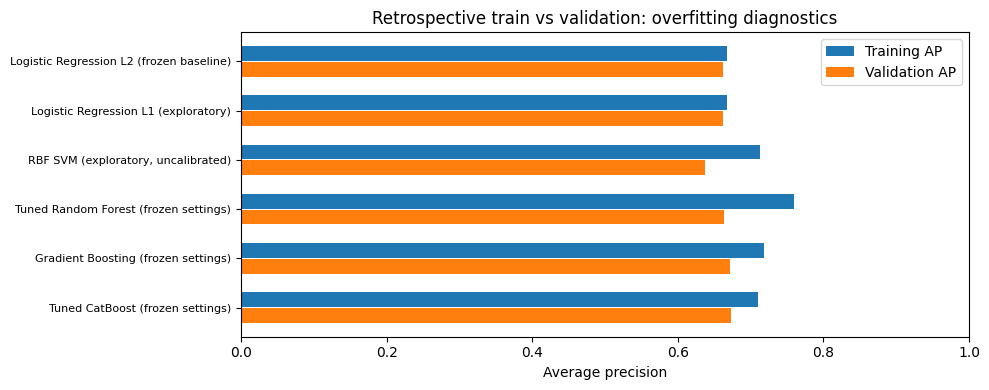

L1 and L2 LR showed similar validation AP (~0.6617). Exploratory RBF SVM achieved ~0.6374. They did not replace the original panel.


In [7]:
display(source_csv('tolerance'))
trainval=source_csv('generalization')
display(trainval[['Model','TrainPR_AUC','ValidationPR_AUC','MeanGap']].round(4))
fig,ax=plt.subplots(figsize=(10,4))
idx=np.arange(len(trainval));ax.barh(idx-.16,trainval.TrainPR_AUC,height=.30,label='Training AP');ax.barh(idx+.16,trainval.ValidationPR_AUC,height=.30,label='Validation AP')
ax.set_yticks(idx,trainval.Model,fontsize=8);ax.invert_yaxis();ax.set_xlim(0,1);ax.set_xlabel('Average precision');ax.legend();ax.set_title('Retrospective train vs validation: overfitting diagnostics');plt.tight_layout();plt.show()
print('L1 and L2 LR showed similar validation AP (~0.6617). Exploratory RBF SVM achieved ~0.6374. They did not replace the original panel.')

## Preprocessing handoff from Member 2
Read the previously saved development OOF preprocessing predictions so the combined disagreement analysis uses aligned customer IDs. This section **loads** the previous preprocessing-policy experiments; it does not rerun them.

In [8]:
pre_p=source_csv('preprocess_pred').set_index('customerID').loc[fold_order].reset_index()
assert (pre_p.customerID.to_numpy()==fold_order.to_numpy()).all()
prep_unstable=pre_p['prep_any_disagreement'].astype(bool)
assert int(prep_unstable.sum())==1114
print(f'Development customers with disagreement across imbalance policies: {prep_unstable.sum()} / {len(pre_p)} ({prep_unstable.mean():.2%})')
display(pre_p[['customerID','pred_BAL-0','pred_BAL-W','pred_BAL-ROS','PrepStabilityFlag']].head(5))

Development customers with disagreement across imbalance policies: 1114 / 5634 (19.77%)


,customerID,pred_BAL-0,pred_BAL-W,pred_BAL-ROS,PrepStabilityFlag
0,4950-BDEUX,0,1,1,Sensitive
1,7993-NQLJE,0,1,1,Sensitive
2,7321-ZNSLA,0,0,0,Stable
3,4922-CVPDX,0,0,0,Stable
4,2903-YYTBW,0,1,1,Sensitive


### 3.4 Four independent sources of customer-level disagreement (archived OOF evidence)
The **four-family diagnostic** includes Logistic Regression, Gradient Boosting, tuned Random Forest and tuned CatBoost, evaluated at 0.50. It differs from the **three-model operational** voting policy at 0.35. Configuration, random-seed and preprocessing-sensitive groups overlap, so we must not add their percentages.

In [9]:
recorded_oof=source_csv('oof').set_index('customerID').loc[fold_order].reset_index()
assert (recorded_oof.ActualChurn.to_numpy()==y_dev.to_numpy()).all()
family=['prob_Logistic_Regression','prob_Gradient_Boosting','prob_Tuned_Random_Forest','prob_Tuned_CatBoost']
fm_votes=recorded_oof[family].ge(.50)
family_flip=fm_votes.nunique(axis=1).gt(1)
stab=source_csv('stability').set_index('customerID').loc[fold_order].reset_index()
config=stab.configuration_any_disagreement.astype(bool)
seed=stab.seed_any_disagreement.astype(bool)
assert int(family_flip.sum())==463 and int(config.sum())==158 and int(seed.sum())==233
flags=pd.DataFrame({'Source':['Imbalance policy','Four model families','Accepted CatBoost settings','Seed (RF + CB)'],
                    'Affected customers':[int(prep_unstable.sum()),int(family_flip.sum()),int(config.sum()),int(seed.sum())]})
flags['Share of development']=100*flags['Affected customers']/len(X_dev)
display(flags.round(2))
quadrants=pd.crosstab(prep_unstable.map({False:'Preprocessing stable',True:'Preprocessing sensitive'}),
                     family_flip.map({False:'Family stable',True:'Family sensitive'}))
display(quadrants)
assert int((prep_unstable & family_flip).sum())==151
print('151 development customers were sensitive to BOTH tested imbalance policy and model family.')

,Source,Affected customers,Share of development
0,Imbalance policy,1114,19.77
1,Four model families,463,8.22
2,Accepted CatBoost settings,158,2.80
3,Seed (RF + CB),233,4.14


col_0,Family sensitive,Family stable
prep_any_disagreement,,
Preprocessing sensitive,151,963
Preprocessing stable,312,4208


151 development customers were sensitive to BOTH tested imbalance policy and model family.


## Member 3 handoff to Member 4
**Frozen panel for evaluation:** tuned CatBoost, Gradient Boosting and tuned Random Forest, selected within an absolute 0.010 development mean-fold AP of the leader. The forest has a larger training–validation gap, so this selection is **not a claim of no overfitting**. The 0.50 disagreement diagnostics are separate from the final operational 0.35 vote threshold.

In [10]:
assert len(recomputed_cv)==6
print('Best recorded tuned CatBoost mean-fold AP ≈ 0.6727; full tuning tables are archived.')
display(source_csv('models_summary').head(7))

Best recorded tuned CatBoost mean-fold AP ≈ 0.6727; full tuning tables are archived.


,model,mean_fold_average_precision,fold_sd,pooled_oof_average_precision,recorded_test_average_precision,scope
0,Logistic Regression,0.661656,0.021638,0.658518,NaN,Development selection; recorded test values ha...
1,Decision Tree,0.613955,0.025822,0.619006,NaN,Development selection; recorded test values ha...
2,Random Forest,0.657463,0.023955,0.653941,NaN,Development selection; recorded test values ha...
3,Gradient Boosting,0.672183,0.023321,0.668539,0.660743,Development selection; recorded test values ha...
4,Tuned Random Forest,0.663856,0.020468,0.660514,0.654652,Development selection; recorded test values ha...
5,CatBoost,0.669118,0.024011,0.664786,NaN,Development selection; recorded test values ha...
6,Tuned CatBoost,0.672731,0.023973,0.669342,0.665842,Development selection; recorded test values ha...


## Member handoff and interpretation
This member notebook is a **stand-alone view** of one part of the shared project. It duplicates the minimum setup needed to run independently. The integrated notebook provides the complete sequential view across Members 1–4. Detailed decision logs and archived results remain in the `decision_logs/` and `model_method_comparison/` folders.

**Do not report saved evidence as a newly rerun search** if the notebook only loads the existing result CSV. Assessments of business benefit require new intervention-outcome data; model agreement is not a correctness guarantee.
